# Phase 4: spatial diagnostic layer (LISA) and policy scenario simulation

Standalone notebook. It rebuilds the primary model of `02_xgboost_xai/ALE_leakage_audit.ipynb` (scenario S2b: 44 features chosen by training gain without `READ_IND_F3`, plus `AGE`) and does four things:

1. **Out-of-fold predictions.** Every individual is scored by a model that did not see their household (5-fold `GroupKFold` on `HHID`). Probabilities are corrected for the `scale_pos_weight` prior shift so they can be averaged into prevalence.
2. **Provincial aggregation.** Observed and predicted illiteracy rates per `PRV` (provinces and HUCs), weighted with `RESP_RFACT_F2`, with cluster-robust standard errors. The residual (observed minus predicted) is the part of a province's rate that its population's composition on the model features does not explain.
3. **Spatial autocorrelation.** Global Moran's I and Local Moran's I (LISA) with permutation inference on the observed rate, the predicted rate and the residual. Queen contiguity, with island units attached to their nearest neighbour; k-nearest-neighbour weights as a sensitivity check.
4. **Scenario simulation.** Selected inputs (internet use, digital skills) are switched on for a share of eligible residents of high-risk provinces, the same out-of-fold models re-score them, and the change in predicted prevalence is reported with Monte Carlo and cluster-bootstrap intervals.

Simulation results are **model-based scenarios, not causal effects**: they show how the fitted model's predictions respond when inputs change, holding everything else fixed.

### Inputs that must be supplied locally

| File | Purpose |
|---|---|
| `../data/PHL-PSA-FLEMMS-2024-V*-PUF/` | Raw FLEMMS CSVs (as in the other notebooks) |
| `../02_xgboost_xai/selected_features_train_only.csv` | Primary model feature list (checked in) |
| `../data/geo/prv_crosswalk.csv` | `PRV` code to name and boundary code. Start from `prv_crosswalk_template.csv` in this folder. |
| `../data/geo/flemms_units.gpkg` **or** `../data/geo/phl_adm3.gpkg` | Boundaries, see section 5 |

Without boundaries the notebook still produces the provincial table and the simulation (targeting the top quintile of observed rates instead of LISA High-High clusters) and skips the LISA cells.

Outputs are written next to this notebook.

In [1]:
import gc, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
N_FOLDS = 5
N_TREES = 300          # same hyperparameters as the primary model
N_PERM = 9999          # LISA permutations
ALPHA = 0.05
KNN_K = 6              # sensitivity weights
SIM_UPTAKE_PP = 0.10   # scenario: +10 percentage points of the eligible universe
SIM_DRAWS = 50         # Monte Carlo draws of who takes up the intervention
SIM_BOOT = 500         # cluster bootstrap replicates for the interval
EXCLUDE_PRV = [999]    # residual code, unresolved (EDA_FINDINGS.md); kept in tables, not in spatial weights

DATA = '../data/PHL-PSA-FLEMMS-2024-V1-PUF/'
DATA2 = '../data/PHL-PSA-FLEMMS-2024-V2-PUF/'
MEMBER_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - MEMBER.CSV'
RTF1_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - RTF1.CSV'
RTF2_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - RTF2.CSV'
RTF3_FILE = DATA2 + 'FLEMMS PUF 2024 Volume2 - RTF3.CSV'
FEATURES_FILE = '../02_xgboost_xai/selected_features_train_only.csv'
EDA_RATES_FILE = '../00_eda/eda_province_rates.csv'

GEO_DIR = '../data/geo/'
CROSSWALK_FILE = GEO_DIR + 'prv_crosswalk.csv'
UNITS_FILE = GEO_DIR + 'flemms_units.gpkg'   # option A: polygons already at PRV level (needs a PRV column)
ADM3_FILE = GEO_DIR + 'phl_adm3.gpkg'        # option B: city/municipality polygons, dissolved via the crosswalk
ADM3_PROV_FIELD = 'ADM2_PCODE'               # province code field in the adm3 file
ADM3_MUN_FIELD = 'ADM3_PCODE'                # city/municipality code field in the adm3 file
PROJ_CRS = 'EPSG:32651'                      # UTM 51N, metric distances for centroids

FIG_DIR = 'lisa_figures'
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Load, merge, filter (same as the ALE notebook)

In [2]:
overlap_cols = ['REG', 'PRV', 'MUN', 'BGY', 'URBANITY', 'REG2']

def drop_overlaps(df, keys):
    return df.drop(columns=[c for c in overlap_cols if c in df.columns and c not in keys])

m = pd.read_csv(MEMBER_FILE)
r1 = drop_overlaps(pd.read_csv(RTF1_FILE), ['HHID'])
r2 = pd.read_csv(RTF2_FILE).rename(columns={'LNO_F2': 'LNO'})
r3 = pd.read_csv(RTF3_FILE).rename(columns={'LNO_F3': 'LNO'})
r2, r3 = drop_overlaps(r2, ['HHID', 'LNO']), drop_overlaps(r3, ['HHID', 'LNO'])

assert not r1['HHID'].duplicated().any()
assert not r2.duplicated(['HHID', 'LNO']).any()
assert not r3.duplicated(['HHID', 'LNO']).any()

df = (m.merge(r1, on='HHID', how='left')
        .merge(r2, on=['HHID', 'LNO'], how='left')
        .merge(r3, on=['HHID', 'LNO'], how='left'))
assert len(df) == len(m), 'merge fan-out'
df = df[(df['AGE'] >= 10) & (df['AGE'] <= 64)].copy()
del m, r1, r2, r3; gc.collect()

df['FLITERATE'] = pd.to_numeric(df['FLITERATE'], errors='coerce')
df = df[df['FLITERATE'].notna() & df['RESP_RFACT_F2'].notna()].reset_index(drop=True)
y = (df['FLITERATE'] == 2).astype(int).to_numpy()   # 1 = functionally illiterate
w = df['RESP_RFACT_F2'].to_numpy(dtype=float)
groups = df['HHID'].to_numpy()
prv = df['PRV'].astype(int).to_numpy()
# cluster for standard errors: the PSU if present, otherwise the household
cluster = (df['PSU'] if 'PSU' in df.columns else df['HHID']).to_numpy()
print('analysis rows:', len(df), '| weighted prevalence:', round(np.average(y, weights=w), 4),
      '| households:', len(np.unique(groups)), '| PRV codes:', len(np.unique(prv)),
      '| SE cluster:', 'PSU' if 'PSU' in df.columns else 'HHID')

analysis rows: 468643 | weighted prevalence: 0.2921 | households: 163655 | PRV codes: 118 | SE cluster: HHID


## 2. Rebuild the primary model's design matrix

Only the variables behind the 45 model columns are encoded. A dummy column `VAR_level` is 1 when the variable (cast to categorical exactly as in the ALE notebook, missing as `Not_Applicable`) equals `level`, which is what `pd.get_dummies` produced there, so the columns are identical. Keeping each variable as a categorical series lets the simulation change a person's level and re-derive every dummy of that variable consistently.

In [3]:
sel = pd.read_csv(FEATURES_FILE)
final_cols = sel['Feature_Name'].tolist()
names = sel.set_index('Feature_Name')['Descriptive_Name'].to_dict()

def as_cat(s):
    if pd.api.types.is_numeric_dtype(s):
        nn = s.dropna()
        if len(nn) and (nn % 1 == 0).all():
            s = s.astype('Int64')
    return s.astype('string').fillna('Not_Applicable')

cand_vars = [c for c in df.columns if c not in ('AGE', 'FLITERATE')]
cat_cache = {}
def cat_of(v):
    if v not in cat_cache:
        cat_cache[v] = as_cat(df[v])
    return cat_cache[v]

# map each dummy column to (source variable, level); verify the level exists so that
# DSKILL_INFO2_1 cannot be mistaken for a level of some shorter prefix
col_src = {}
for col in final_cols:
    if col == 'AGE':
        continue
    hits = [v for v in cand_vars if col.startswith(v + '_')
            and col[len(v) + 1:] in set(cat_of(v).unique())]
    assert len(hits) == 1, f'{col}: source variable ambiguous or missing {hits}'
    col_src[col] = (hits[0], col[len(hits[0]) + 1:])

model_vars = sorted({v for v, _ in col_src.values()})
cats = pd.DataFrame({v: cat_of(v) for v in model_vars})
del cat_cache; gc.collect()

def encode(cats_frame, age):
    X = pd.DataFrame({col: (cats_frame[v].to_numpy() == lvl).astype(np.uint8)
                      for col, (v, lvl) in col_src.items()})
    X.insert(0, 'AGE', age)
    return X[final_cols]

age = df['AGE'].fillna(df['AGE'].median()).astype(float).to_numpy()
X = encode(cats, age)
const = [c for c in final_cols if X[c].nunique() <= 1]
assert not const, f'constant model columns (encoding mismatch?): {const}'
print('design matrix:', X.shape, '| source variables:', len(model_vars))

design matrix: (468643, 45) | source variables: 34


## 3. Out-of-fold predictions

5-fold `GroupKFold` on `HHID`: each person is predicted by the fold model trained without their household. The feature list was selected on the ALE notebook's 80% training split, so for those rows the selection step (not the fitted model) has seen them; the effect of this on AUC was measured there as about 0.001.

**Prior correction.** `scale_pos_weight = s` multiplies the weight of the illiterate class by `s`, which inflates the fitted odds by roughly `s`. Subtracting `log(s)` from the margin undoes this, so averaged probabilities estimate prevalence. Calibration is checked below by weighted deciles; a single intercept shift (calibration in the large) is applied only if the corrected mean still misses the observed prevalence by more than 0.5 percentage points.

In [4]:
def make_model(yy):
    spw = (yy == 0).sum() / max((yy == 1).sum(), 1)
    mdl = XGBClassifier(n_estimators=N_TREES, learning_rate=0.05, max_depth=6,
                        scale_pos_weight=spw, tree_method='hist',
                        random_state=SEED, eval_metric='auc', n_jobs=-1)
    return mdl, spw

fold = np.full(len(y), -1)
fold_models, fold_spw = [], []
margin_oof = np.zeros(len(y))
for k, (tr, te) in enumerate(GroupKFold(n_splits=N_FOLDS).split(X, y, groups)):
    mdl, spw = make_model(y[tr])
    mdl.fit(X.iloc[tr], y[tr], sample_weight=w[tr])
    margin_oof[te] = mdl.predict(X.iloc[te], output_margin=True) - np.log(spw)
    fold[te] = k
    fold_models.append(mdl); fold_spw.append(spw)
    print(f'fold {k}: train {len(tr):,} test {len(te):,} spw {spw:.3f}')
    gc.collect()
assert (fold >= 0).all()

sigmoid = lambda z: 1 / (1 + np.exp(-z))
prev = np.average(y, weights=w)
p_prior = sigmoid(margin_oof)
gap = np.average(p_prior, weights=w) - prev

INTERCEPT = 0.0
if abs(gap) > 0.005:
    lo, hi = -5.0, 5.0
    for _ in range(60):                       # bisection on the weighted mean
        mid = (lo + hi) / 2
        if np.average(sigmoid(margin_oof + mid), weights=w) > prev: hi = mid
        else: lo = mid
    INTERCEPT = (lo + hi) / 2

def score(frame_rows, fold_idx):
    """Calibrated probability for rows in `frame_rows`, each scored by its own fold model."""
    out = np.empty(len(frame_rows))
    for k, mdl in enumerate(fold_models):
        msk = fold_idx == k
        if msk.any():
            out[msk] = mdl.predict(frame_rows[msk], output_margin=True) - np.log(fold_spw[k]) + INTERCEPT
    return sigmoid(out)

p_oof = sigmoid(margin_oof + INTERCEPT)
metrics = pd.DataFrame([{
    'roc_auc_weighted_oof': roc_auc_score(y, p_oof, sample_weight=w),
    'pr_auc_weighted_oof': average_precision_score(y, p_oof, sample_weight=w),
    'roc_auc_unweighted_oof': roc_auc_score(y, p_oof),
    'observed_prevalence_w': prev,
    'mean_pred_after_prior_correction_w': np.average(p_prior, weights=w),
    'intercept_shift_applied': INTERCEPT,
    'mean_pred_final_w': np.average(p_oof, weights=w)}])
metrics.to_csv('oof_model_metrics.csv', index=False)
print(metrics.T.round(4).to_string(header=False))

fold 0: train 374,914 test 93,729 spw 2.277


fold 1: train 374,914 test 93,729 spw 2.271


fold 2: train 374,914 test 93,729 spw 2.270


fold 3: train 374,915 test 93,728 spw 2.266


fold 4: train 374,915 test 93,728 spw 2.270


roc_auc_weighted_oof                0.7009
pr_auc_weighted_oof                 0.5073
roc_auc_unweighted_oof              0.7087
observed_prevalence_w               0.2921
mean_pred_after_prior_correction_w  0.2902
intercept_shift_applied             0.0000
mean_pred_final_w                   0.2902


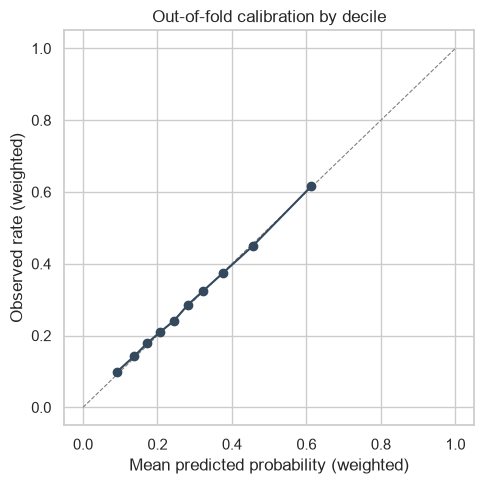

,decile,n,mean_pred_w,observed_w
0,1,40459.0,0.090,0.098
1,2,42822.0,0.138,0.142
2,3,43803.0,0.173,0.179
3,4,44163.0,0.208,0.211
4,5,44850.0,0.244,0.240
5,6,45466.0,0.281,0.286
6,7,47200.0,0.323,0.325
7,8,49502.0,0.376,0.374
8,9,52332.0,0.456,0.449
9,10,58046.0,0.614,0.616


In [5]:
# calibration by weighted deciles of predicted risk
order = np.argsort(p_oof)
cw = np.cumsum(w[order]) / w.sum()
dec = np.empty(len(y), dtype=int); dec[order] = np.minimum((cw * 10).astype(int), 9)
cal = (pd.DataFrame({'decile': dec + 1, 'y': y, 'p': p_oof, 'w': w})
         .groupby('decile')
         .apply(lambda d: pd.Series({'n': len(d),
                                     'mean_pred_w': np.average(d['p'], weights=d['w']),
                                     'observed_w': np.average(d['y'], weights=d['w'])}))
         .reset_index())
cal.to_csv('oof_calibration_deciles.csv', index=False)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color='grey', lw=0.8, ls='--')
ax.plot(cal['mean_pred_w'], cal['observed_w'], marker='o', color='#34495e')
ax.set_xlabel('Mean predicted probability (weighted)'); ax.set_ylabel('Observed rate (weighted)')
ax.set_title('Out-of-fold calibration by decile')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'oof_calibration.png'), dpi=200); plt.show()
cal.round(3)

## 4. Provincial aggregation

Per `PRV`: weighted observed rate, weighted mean predicted probability, residual, and a linearised standard error for each rate treating the cluster (PSU, or household if no PSU column) as the sampling unit. Stratification is ignored, so the standard errors are on the conservative side. The observed rate is cross-checked against the EDA table.

In [6]:
def ratio_se(vals, wts, clus):
    """SE of a weighted mean (ratio estimator) with clusters as the sampling unit."""
    r = np.average(vals, weights=wts)
    e = pd.Series(wts * (vals - r)).groupby(clus).sum().to_numpy()
    nc = len(e)
    return np.sqrt(nc / max(nc - 1, 1) * np.sum(e ** 2)) / wts.sum()

rows = []
for code_, idx in pd.Series(np.arange(len(y))).groupby(prv):
    i = idx.to_numpy()
    rows.append({'PRV': int(code_), 'n': len(i), 'n_clusters': len(np.unique(cluster[i])),
                 'pop_weighted': w[i].sum(),
                 'obs_rate': np.average(y[i], weights=w[i]),
                 'obs_se': ratio_se(y[i], w[i], cluster[i]),
                 'pred_rate': np.average(p_oof[i], weights=w[i]),
                 'pred_se': ratio_se(p_oof[i], w[i], cluster[i])})
prov = pd.DataFrame(rows)
prov['residual'] = prov['obs_rate'] - prov['pred_rate']
prov['obs_cv'] = prov['obs_se'] / prov['obs_rate']

if os.path.exists(EDA_RATES_FILE):
    eda = pd.read_csv(EDA_RATES_FILE)[['PRV', 'w_rate']]
    chk = prov.merge(eda, on='PRV', how='outer', indicator=True)
    diff = (chk['obs_rate'] - chk['w_rate']).abs().max()
    print('codes only in one table:', chk.loc[chk['_merge'] != 'both', 'PRV'].tolist())
    print(f'max |obs_rate - EDA w_rate| = {diff:.2e}', '(OK)' if diff < 1e-6 else '(CHECK: universes differ)')

print(f"corr(observed, predicted) across PRV = {prov['obs_rate'].corr(prov['pred_rate']):.3f}")
print('residual range:', prov['residual'].min().round(3), 'to', prov['residual'].max().round(3))

codes only in one table: []
max |obs_rate - EDA w_rate| = 1.11e-16 (OK)
corr(observed, predicted) across PRV = 0.771
residual range: -0.178 to 0.174


## 5. Boundaries and the PRV crosswalk

FLEMMS identifies areas only by numeric `PRV` codes, and no name or boundary crosswalk is in the repo (`[DATA MISSING]`, `PROJECT_PLAN.md` decision 4). Two ways to supply geometry:

- **Option A.** `flemms_units.gpkg`: one polygon per FLEMMS unit with an integer `PRV` column. Use this if the units have already been built in GIS.
- **Option B.** `phl_adm3.gpkg`: city/municipality polygons (for example the PSA/NAMRIA administrative boundaries distributed on HDX), plus `prv_crosswalk.csv` with one row per `PRV`:

| Column | Meaning |
|---|---|
| `PRV` | FLEMMS code |
| `NAME` | Province or city name |
| `UNIT_TYPE` | `province` or `lgu` (an HUC or other city/municipality reported separately) |
| `PSGC_PROV` | For `province` rows: the province code(s) as they appear in `ADM3_PROV_FIELD`, `;`-separated |
| `PSGC_MUN` | For `lgu` rows: the city code(s) as they appear in `ADM3_MUN_FIELD`, `;`-separated |

A `province` unit is every adm3 polygon with that province code, minus the polygons claimed by `lgu` rows, so HUCs are carved out of the province that surrounds them. `prv_crosswalk_template.csv` in this folder lists all 118 codes with their sample size and weighted rate to help identification. The mapping must come from the PSA codebook or PSA directly, not from guessing by code order.

In [7]:
import importlib.util
HAVE_GEO_LIBS = all(importlib.util.find_spec(m) for m in ('geopandas', 'libpysal', 'esda'))

def load_crosswalk():
    if not os.path.exists(CROSSWALK_FILE):
        return None
    cw_ = pd.read_csv(CROSSWALK_FILE, dtype=str)
    cw_['PRV'] = cw_['PRV'].astype(int)
    return cw_

def split_codes(s):
    return [c.strip() for c in str(s).split(';') if c.strip() and c.strip().lower() != 'nan']

def build_units_from_adm3(cw_):
    adm3 = gpd.read_file(ADM3_FILE)
    adm3[ADM3_PROV_FIELD] = adm3[ADM3_PROV_FIELD].astype(str).str.strip()
    adm3[ADM3_MUN_FIELD] = adm3[ADM3_MUN_FIELD].astype(str).str.strip()
    owner = pd.Series(np.nan, index=adm3.index)
    lgu = cw_[cw_['UNIT_TYPE'].str.lower() == 'lgu']
    for _, r in lgu.iterrows():                      # cities first, so they are carved out
        hit = adm3[ADM3_MUN_FIELD].isin(split_codes(r['PSGC_MUN']))
        assert hit.any(), f"PRV {r['PRV']}: no adm3 polygon for {r['PSGC_MUN']}"
        assert owner[hit].isna().all(), f"PRV {r['PRV']}: polygon already assigned"
        owner[hit] = r['PRV']
    for _, r in cw_[cw_['UNIT_TYPE'].str.lower() == 'province'].iterrows():
        hit = adm3[ADM3_PROV_FIELD].isin(split_codes(r['PSGC_PROV'])) & owner.isna()
        assert hit.any(), f"PRV {r['PRV']}: no adm3 polygon for {r['PSGC_PROV']}"
        owner[hit] = r['PRV']
    if owner.isna().any():
        print(f'{owner.isna().sum()} adm3 polygons not assigned to any PRV (left out of the map)')
    adm3['PRV'] = owner
    return adm3[adm3['PRV'].notna()].dissolve(by='PRV').reset_index().astype({'PRV': int})[['PRV', 'geometry']]

cw = load_crosswalk()
units = None
if not HAVE_GEO_LIBS:
    print('geopandas / libpysal / esda not installed: spatial cells will be skipped')
else:
    import geopandas as gpd
    from libpysal.weights import Queen, KNN, attach_islands
    from esda.moran import Moran, Moran_Local
    if os.path.exists(UNITS_FILE):
        units = gpd.read_file(UNITS_FILE)[['PRV', 'geometry']].astype({'PRV': int})
        print('geometry: option A,', UNITS_FILE)
    elif os.path.exists(ADM3_FILE) and cw is not None:
        units = build_units_from_adm3(cw)
        print('geometry: option B, dissolved from', ADM3_FILE)
    else:
        print('No boundaries found (need', UNITS_FILE, 'or', ADM3_FILE, '+', CROSSWALK_FILE, ')')

prov['NAME'] = prov['PRV'].map(cw.set_index('PRV')['NAME']) if cw is not None else np.nan
prov['NAME'] = prov['NAME'].fillna(prov['PRV'].astype(str))
HAVE_GEO = units is not None
if HAVE_GEO:
    units = units.to_crs(PROJ_CRS)
    missing_geo = sorted(set(prov['PRV']) - set(units['PRV']))
    extra_geo = sorted(set(units['PRV']) - set(prov['PRV']))
    print('PRV with data but no polygon:', missing_geo)
    print('polygons with no data:', extra_geo)
    gdf = units.merge(prov, on='PRV', how='inner')
    gdf = gdf[~gdf['PRV'].isin(EXCLUDE_PRV)].sort_values('PRV').reset_index(drop=True)
    print('spatial units:', len(gdf))

No boundaries found (need ../data/geo/flemms_units.gpkg or ../data/geo/phl_adm3.gpkg + ../data/geo/prv_crosswalk.csv )


## 6. Spatial weights

Primary: queen contiguity. Units with no contiguous neighbour (island provinces) are attached to their single nearest neighbour by centroid distance, so that no unit is dropped. Sensitivity: k-nearest neighbours with `k = 6`. Both are row-standardised.

In [8]:
def build_weights(g):
    g = g.set_index('PRV', drop=False)
    wq = Queen.from_dataframe(g, use_index=True)
    islands = list(wq.islands)
    cent = g.copy(); cent['geometry'] = g.geometry.centroid
    if islands:
        wq = attach_islands(wq, KNN.from_dataframe(cent, k=1, use_index=True))
    wk = KNN.from_dataframe(cent, k=KNN_K, use_index=True)
    for ww in (wq, wk):
        ww.transform = 'r'
    return wq, wk, islands

if HAVE_GEO:
    W_queen, W_knn, islands = build_weights(gdf)
    assert list(W_queen.id_order) == gdf['PRV'].tolist()
    wsum = pd.DataFrame([
        {'weights': 'queen + nearest for islands', 'n_units': W_queen.n,
         'islands_attached': len(islands), 'mean_neighbours': W_queen.mean_neighbors,
         'components': W_queen.n_components},
        {'weights': f'knn k={KNN_K}', 'n_units': W_knn.n, 'islands_attached': 0,
         'mean_neighbours': W_knn.mean_neighbors, 'components': W_knn.n_components}])
    wsum.to_csv('spatial_weights_summary.csv', index=False)
    print('island units attached by nearest neighbour:', islands)
    display(wsum)

## 7. Global Moran's I and LISA

LISA quadrants: High-High (a high-rate unit surrounded by high-rate units), Low-Low, High-Low and Low-High (spatial outliers). A unit is reported in its quadrant when its permutation p-value is below 0.05. Because 117 local tests are run, a Benjamini-Hochberg false discovery rate column is reported as well; the manuscript should state which rule it uses.

Three variables:

- `obs_rate`: where illiteracy is concentrated (Objective 1).
- `pred_rate`: where the model expects it to be, from population composition alone.
- `residual`: clusters the model features do not explain. These point to place-level factors outside the model.

In [9]:
LISA_VARS = ['obs_rate', 'pred_rate', 'residual']
QUAD = {1: 'High-High', 2: 'Low-High', 3: 'Low-Low', 4: 'High-Low'}

def bh_cutoff(p, alpha=ALPHA):
    ps = np.sort(p); m_ = len(ps)
    ok = ps <= alpha * np.arange(1, m_ + 1) / m_
    return ps[ok].max() if ok.any() else 0.0

if HAVE_GEO:
    glob, lisa = [], []
    for v in LISA_VARS:
        z = gdf[v].to_numpy()
        for wname, ww in (('queen', W_queen), (f'knn{KNN_K}', W_knn)):
            mi = Moran(z, ww, permutations=N_PERM)
            glob.append({'variable': v, 'weights': wname, 'I': mi.I, 'E_I': mi.EI,
                         'z_sim': mi.z_sim, 'p_sim': mi.p_sim})
        lm = Moran_Local(z, W_queen, permutations=N_PERM, seed=SEED)
        cut = bh_cutoff(lm.p_sim)
        quad = pd.Series(lm.q).map(QUAD)
        lisa.append(pd.DataFrame({
            'PRV': gdf['PRV'], 'NAME': gdf['NAME'], 'variable': v, 'value': z,
            'local_I': lm.Is, 'p_sim': lm.p_sim, 'quadrant': quad,
            'cluster_p05': np.where(lm.p_sim < ALPHA, quad, 'Not significant'),
            'cluster_fdr': np.where(lm.p_sim <= cut, quad, 'Not significant')}))
    glob = pd.DataFrame(glob); lisa = pd.concat(lisa, ignore_index=True)
    glob.to_csv('global_morans_i.csv', index=False)
    lisa.to_csv('lisa_clusters.csv', index=False)
    display(glob.round(4))
    display(lisa.groupby(['variable', 'cluster_p05']).size().unstack(fill_value=0))

In [10]:
LISA_COLORS = {'High-High': '#d7191c', 'High-Low': '#fdae61', 'Low-High': '#abd9e9',
               'Low-Low': '#2c7bb6', 'Not significant': '#e0e0e0'}

if HAVE_GEO:
    excl = units[units['PRV'].isin(EXCLUDE_PRV)]
    # choropleths
    fig, axes = plt.subplots(1, 3, figsize=(18, 9))
    for ax, v, cmap, title in zip(axes, LISA_VARS, ['Reds', 'Reds', 'RdBu_r'],
                                  ['Observed rate', 'Predicted rate', 'Residual (obs - pred)']):
        kw = {}
        if v == 'residual':
            lim = gdf[v].abs().max(); kw = {'vmin': -lim, 'vmax': lim}
        gdf.plot(column=v, cmap=cmap, legend=True, ax=ax, edgecolor='white', linewidth=0.2,
                 legend_kwds={'shrink': 0.5}, **kw)
        if len(excl): excl.plot(ax=ax, color='none', edgecolor='k', hatch='///', linewidth=0.3)
        ax.set_title(title); ax.set_axis_off()
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'choropleth_rates.png'), dpi=200); plt.show()

    # LISA cluster maps
    fig, axes = plt.subplots(1, 3, figsize=(18, 9))
    for ax, v in zip(axes, LISA_VARS):
        lab = lisa.loc[lisa['variable'] == v, 'cluster_p05'].to_numpy()
        g = gdf.assign(cluster=lab)
        for k_, col in LISA_COLORS.items():
            sub = g[g['cluster'] == k_]
            if len(sub): sub.plot(ax=ax, color=col, edgecolor='white', linewidth=0.2)
        ax.set_title(f'LISA clusters: {v} (p < {ALPHA}, queen)'); ax.set_axis_off()
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in LISA_COLORS.values()]
    fig.legend(handles, LISA_COLORS.keys(), loc='lower center', ncol=5)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'lisa_cluster_maps.png'), dpi=200); plt.show()

    # Moran scatterplot for the observed rate
    from libpysal.weights import lag_spatial
    z = gdf['obs_rate'].to_numpy(); zs = (z - z.mean()) / z.std()
    lag = lag_spatial(W_queen, zs)
    lab = lisa.loc[lisa['variable'] == 'obs_rate', 'cluster_p05'].to_numpy()
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(zs, lag, c=[LISA_COLORS[l] for l in lab], edgecolor='k', linewidth=0.3)
    b = np.polyfit(zs, lag, 1); xx = np.linspace(zs.min(), zs.max(), 2)
    ax.plot(xx, b[0] * xx + b[1], color='k', lw=0.8)
    ax.axhline(0, color='grey', lw=0.6); ax.axvline(0, color='grey', lw=0.6)
    ax.set_xlabel('Observed rate (standardised)'); ax.set_ylabel('Spatial lag')
    I_obs = glob.loc[(glob['variable'] == 'obs_rate') & (glob['weights'] == 'queen'), 'I'].iloc[0]
    ax.set_title(f'Moran scatterplot, I = {I_obs:.3f}')
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'moran_scatter_obs.png'), dpi=200); plt.show()

## 8. Target provinces for the simulation

High-High units of the observed rate (p < 0.05). If no boundaries are available, or no High-High cluster is found, the top quintile of observed rates is used instead, and the notebook says which rule was applied.

In [11]:
TARGET_RULE = None
if HAVE_GEO:
    hh = lisa.query("variable == 'obs_rate' and cluster_p05 == 'High-High'")['PRV'].tolist()
    if hh:
        target_prv, TARGET_RULE = hh, 'LISA High-High, observed rate, p < 0.05'
if TARGET_RULE is None:
    cand = prov[~prov['PRV'].isin(EXCLUDE_PRV)]
    target_prv = cand.loc[cand['obs_rate'] >= cand['obs_rate'].quantile(0.8), 'PRV'].tolist()
    TARGET_RULE = 'top quintile of observed rate (fallback)'
print('target rule:', TARGET_RULE)
print('target PRV:', target_prv)
in_target = np.isin(prv, target_prv)
print(f'target rows {in_target.sum():,} | weighted population share {w[in_target].sum() / w.sum():.3f}')

target rule: top quintile of observed rate (fallback)
target PRV: [2, 7, 16, 22, 26, 28, 35, 36, 41, 45, 48, 55, 60, 64, 65, 67, 68, 70, 72, 73, 80, 83, 85, 86]
target rows 102,256 | weighted population share 0.201


## 9. Scenario simulation

Each scenario sets one or more variables to a target level for selected people.

- **Universe.** People asked the internet question (`INTERNET` not `Not_Applicable`), so the scenario does not assign internet use to people outside the question's universe. *The universe definitions for `INTERNET` and the `DSKILL_*` items should be checked against the Form 3 questionnaire, which is not in the repo.*
- **Eligible.** People in the universe who are not already at the target level on every scenario variable.
- **Uptake.** In each target province, eligible people are drawn at random, each with equal probability, until the weighted share of the universe at the target state rises by `SIM_UPTAKE_PP` (10 percentage points), or everyone eligible is used.
- **Scoring.** Every person is re-scored by their own out-of-fold model, so the baseline is exactly `p_oof`. The effect is the change in weighted mean predicted probability over **all** residents of the province, in percentage points.
- **Uncertainty.** `SIM_DRAWS` draws of who takes up the intervention give the Monte Carlo spread; a cluster bootstrap of the per-person effect (averaged over draws) gives a sampling interval. Neither covers model uncertainty from refitting.

`DSKILL_*` items in the model are switched as a block, because they are strongly correlated and switching one alone produces combinations the data rarely contain.

In [12]:
dskill_vars = [v for v in model_vars if v.startswith('DSKILL')]
SCENARIOS = {
    'internet':        {'INTERNET': '1'},
    'digital_skills':  {v: '1' for v in dskill_vars},
    'digital_package': {'INTERNET': '1', **{v: '1' for v in dskill_vars}},
}
UNIVERSE_VAR = 'INTERNET'
for s, spec in SCENARIOS.items():
    for v, lvl in spec.items():
        assert v in cats.columns, f'{s}: {v} is not a model variable'
        assert lvl in set(cats[v].unique()), f'{s}: level {lvl!r} not observed for {v}'
print({s: list(spec) for s, spec in SCENARIOS.items()})

rng = np.random.default_rng(SEED)
t_idx = np.where(in_target)[0]
cats_t = cats.iloc[t_idx].reset_index(drop=True)
age_t, w_t, prv_t, fold_t, clus_t = age[t_idx], w[t_idx], prv[t_idx], fold[t_idx], cluster[t_idx]
p_base_t = p_oof[t_idx]
universe_t = cats_t[UNIVERSE_VAR].to_numpy() != 'Not_Applicable'

def draw_switch(at_target):
    """Boolean mask of people switched in one draw, per target province."""
    sw = np.zeros(len(at_target), dtype=bool)
    for code_ in np.unique(prv_t):
        in_p = (prv_t == code_) & universe_t
        need = SIM_UPTAKE_PP * w_t[in_p].sum()
        elig = np.where(in_p & ~at_target)[0]
        if not len(elig): continue
        elig = rng.permutation(elig)
        take = np.cumsum(w_t[elig]) <= need
        sw[elig[take]] = True
    return sw

sim_rows, nat_rows, boot_rows = [], [], []
for s, spec in SCENARIOS.items():
    at_target = np.all([cats_t[v].to_numpy() == lvl for v, lvl in spec.items()], axis=0)
    delta_sum = np.zeros(len(t_idx)); draw_eff = []
    for d in range(SIM_DRAWS):
        sw = draw_switch(at_target)
        c_new = cats_t.loc[sw].copy()            # only the switched rows change
        for v, lvl in spec.items():
            c_new[v] = lvl
        X_new = encode(c_new, age_t[sw])
        delta = np.zeros(len(t_idx))
        delta[sw] = score(X_new, fold_t[sw]) - p_base_t[sw]
        delta_sum += delta
        draw_eff.append(pd.Series(w_t * delta).groupby(prv_t).sum() / pd.Series(w_t).groupby(prv_t).sum())
        draw_eff[-1]['__all__'] = np.sum(w_t * delta) / w_t.sum()
        draw_eff[-1]['__share_switched__'] = w_t[sw].sum() / w_t[universe_t].sum()
    de = pd.DataFrame(draw_eff)
    delta_bar = delta_sum / SIM_DRAWS

    # cluster bootstrap of the draw-averaged per-person effect, within each province
    boot = {}
    for code_ in np.unique(prv_t):
        i = np.where(prv_t == code_)[0]
        cl = pd.DataFrame({'c': clus_t[i], 'wd': w_t[i] * delta_bar[i], 'w': w_t[i]}).groupby('c').sum()
        b_idx = rng.integers(0, len(cl), size=(SIM_BOOT, len(cl)))
        boot[code_] = cl['wd'].to_numpy()[b_idx].sum(1) / cl['w'].to_numpy()[b_idx].sum(1)
    for code_ in np.unique(prv_t):
        i = prv_t == code_
        sim_rows.append({'scenario': s, 'PRV': int(code_),
                         'baseline_pred_rate': np.average(p_base_t[i], weights=w_t[i]),
                         'effect_pp': 100 * de[code_].mean(),
                         'mc_lo_pp': 100 * de[code_].quantile(0.025), 'mc_hi_pp': 100 * de[code_].quantile(0.975),
                         'boot_lo_pp': 100 * np.quantile(boot[code_], 0.025),
                         'boot_hi_pp': 100 * np.quantile(boot[code_], 0.975),
                         'eligible_share_w': w_t[i & universe_t & ~at_target].sum() / max(w_t[i & universe_t].sum(), 1e-12)})
    nat_target = de['__all__']
    nat_rows.append({'scenario': s, 'variables': ', '.join(spec),
                     'target_rule': TARGET_RULE, 'n_target_units': len(np.unique(prv_t)),
                     'share_universe_switched_w': de['__share_switched__'].mean(),
                     'effect_target_pop_pp': 100 * nat_target.mean(),
                     'mc_lo_pp': 100 * nat_target.quantile(0.025), 'mc_hi_pp': 100 * nat_target.quantile(0.975),
                     'effect_national_pp': 100 * nat_target.mean() * w_t.sum() / w.sum()})
    print(f"{s}: {100 * nat_target.mean():+.2f} pp in target provinces")
    gc.collect()

sim = pd.DataFrame(sim_rows)
sim['NAME'] = sim['PRV'].map(prov.set_index('PRV')['NAME'])
sim['scenario_pred_rate'] = sim['baseline_pred_rate'] + sim['effect_pp'] / 100
nat = pd.DataFrame(nat_rows)
sim.to_csv('simulation_province_effects.csv', index=False)
nat.to_csv('simulation_summary.csv', index=False)
display(nat.round(3))

{'internet': ['INTERNET'], 'digital_skills': ['DSKILL_CONT1', 'DSKILL_CONT2', 'DSKILL_CONT3', 'DSKILL_INFO1', 'DSKILL_INFO2', 'DSKILL_PROB6', 'DSKILL_SAFE2'], 'digital_package': ['INTERNET', 'DSKILL_CONT1', 'DSKILL_CONT2', 'DSKILL_CONT3', 'DSKILL_INFO1', 'DSKILL_INFO2', 'DSKILL_PROB6', 'DSKILL_SAFE2']}


internet: -0.28 pp in target provinces


digital_skills: -0.91 pp in target provinces


digital_package: -1.08 pp in target provinces


,scenario,variables,target_rule,n_target_units,share_universe_switched_w,effect_target_pop_pp,mc_lo_pp,mc_hi_pp,effect_national_pp
0,internet,INTERNET,top quintile of observed rate (fallback),24,0.1,-0.285,-0.293,-0.277,-0.057
1,digital_skills,"DSKILL_CONT1, DSKILL_CONT2, DSKILL_CONT3, DSKI...",top quintile of observed rate (fallback),24,0.1,-0.909,-0.924,-0.893,-0.182
2,digital_package,"INTERNET, DSKILL_CONT1, DSKILL_CONT2, DSKILL_C...",top quintile of observed rate (fallback),24,0.1,-1.077,-1.093,-1.050,-0.216


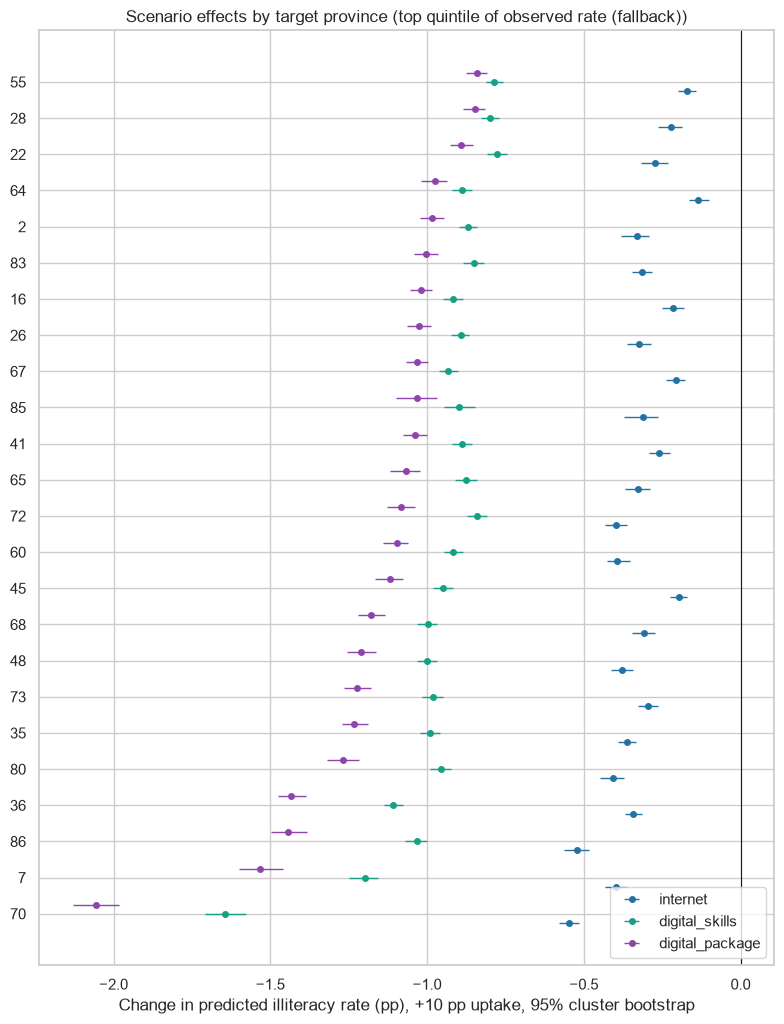

In [13]:
fig, ax = plt.subplots(figsize=(8, 0.35 * sim['PRV'].nunique() + 2))
order_ = (sim.query("scenario == 'digital_package'").sort_values('effect_pp')['NAME']).tolist()
pal = dict(zip(SCENARIOS, ['#2471a3', '#16a085', '#8e44ad']))
for j, (s, g) in enumerate(sim.groupby('scenario', sort=False)):
    g = g.set_index('NAME').loc[order_]
    ypos = np.arange(len(g)) + (j - 1) * 0.25
    ax.errorbar(g['effect_pp'], ypos,
                xerr=[g['effect_pp'] - g['boot_lo_pp'], g['boot_hi_pp'] - g['effect_pp']],
                fmt='o', color=pal[s], label=s, ms=4, lw=1)
ax.set_yticks(np.arange(len(order_))); ax.set_yticklabels(order_)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel(f'Change in predicted illiteracy rate (pp), +{int(SIM_UPTAKE_PP * 100)} pp uptake, 95% cluster bootstrap')
ax.set_title(f'Scenario effects by target province ({TARGET_RULE})')
ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'simulation_effects.png'), dpi=200); plt.show()

In [14]:
out = prov.copy()
if HAVE_GEO:
    wide = lisa.pivot(index='PRV', columns='variable', values='cluster_p05').add_prefix('lisa_')
    out = out.merge(wide, left_on='PRV', right_index=True, how='left')
out['sim_target'] = out['PRV'].isin(target_prv)
out.to_csv('province_rates_observed_predicted.csv', index=False)
print('written:', sorted(f for f in os.listdir('.') if f.endswith('.csv')))

written: ['oof_calibration_deciles.csv', 'oof_model_metrics.csv', 'province_rates_observed_predicted.csv', 'prv_crosswalk_template.csv', 'simulation_province_effects.csv', 'simulation_summary.csv']
